# Image Classification Using a Neural Network in R

This experiment uses a small generated dataset of **apples and bananas**. It prepares the images, trains a neural network using Keras 3, and evaluates how well the model predicts the two categories.

The dataset contains 12 JPEG images: 6 apples and 6 bananas.


## 1. Install and Load Packages

In [1]:
install.packages(c("jpeg", "keras3"))

Installing packages into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependencies ‘RcppTOML’, ‘here’, ‘png’, ‘config’, ‘tfautograph’, ‘reticulate’, ‘tensorflow’, ‘tfruns’, ‘zeallot’, ‘dotty’




In [2]:
library(jpeg)
library(keras3)

## 2. Extract and Read the Dataset


In [3]:
zip_path <- "/content/apple_banana_dataset.zip"
extract_path <- "/content"

if (!file.exists(zip_path)) {
  stop("Place apple_banana_dataset.zip in /content before running this notebook.")
}

unzip(zip_path, exdir = extract_path)
image_dir <- "/content/apple_banana_dataset/images"

image_files <- c(
  paste0("apple", 1:6, ".jpg"),
  paste0("banana", 1:6, ".jpg")
)

image_paths <- file.path(image_dir, image_files)
stopifnot(all(file.exists(image_paths)))

pics <- lapply(image_paths, readJPEG)
names(pics) <- image_files

length(pics)

[1] 12

## 3. Explore the Images

Display a few examples and inspect the structure of an image.

Warning message in rasterImage(x, 0, 0, ncol(x), nrow(x), ...):
“"axes" is not a graphical parameter”
Warning message in rasterImage(x, 0, 0, ncol(x), nrow(x), ...):
“"axes" is not a graphical parameter”
Warning message in rasterImage(x, 0, 0, ncol(x), nrow(x), ...):
“"axes" is not a graphical parameter”
Warning message in rasterImage(x, 0, 0, ncol(x), nrow(x), ...):
“"axes" is not a graphical parameter”
Warning message in rasterImage(x, 0, 0, ncol(x), nrow(x), ...):
“"axes" is not a graphical parameter”
Warning message in rasterImage(x, 0, 0, ncol(x), nrow(x), ...):
“"axes" is not a graphical parameter”


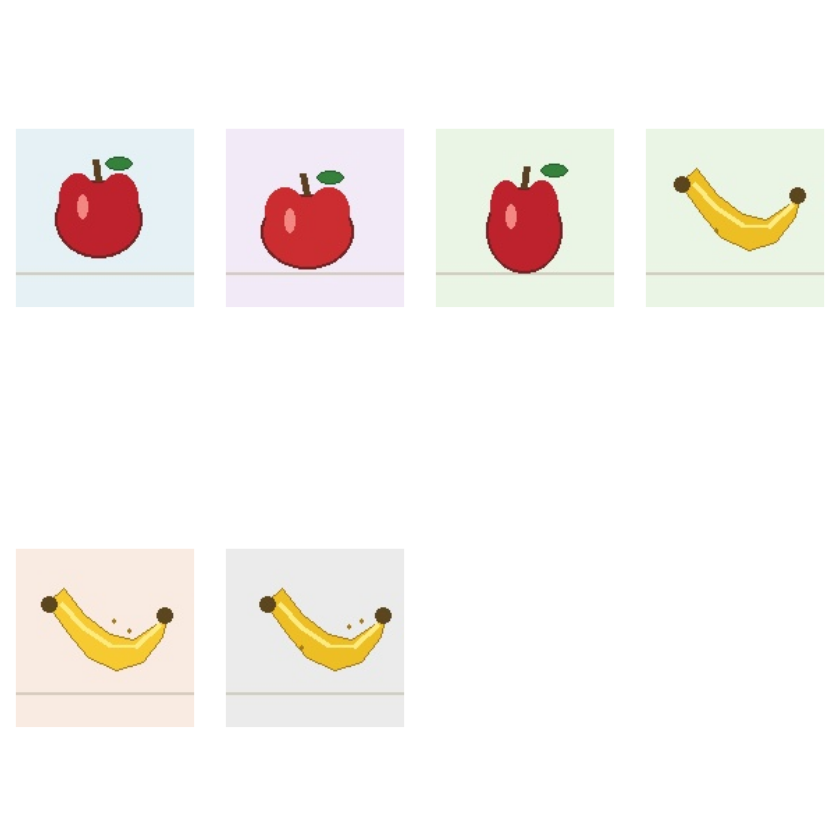

In [4]:
par(mfrow = c(2, 4), mar = c(1, 1, 2, 1))

for (i in c(1, 2, 3, 7, 8, 9)) {
  plot(as.raster(pics[[i]]), main = image_files[i], axes = FALSE)
}

par(mfrow = c(1, 1))

In [5]:
summary(as.numeric(pics[[1]]))

   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
0.08235 0.90196 0.93725 0.81371 0.95294 1.00000 

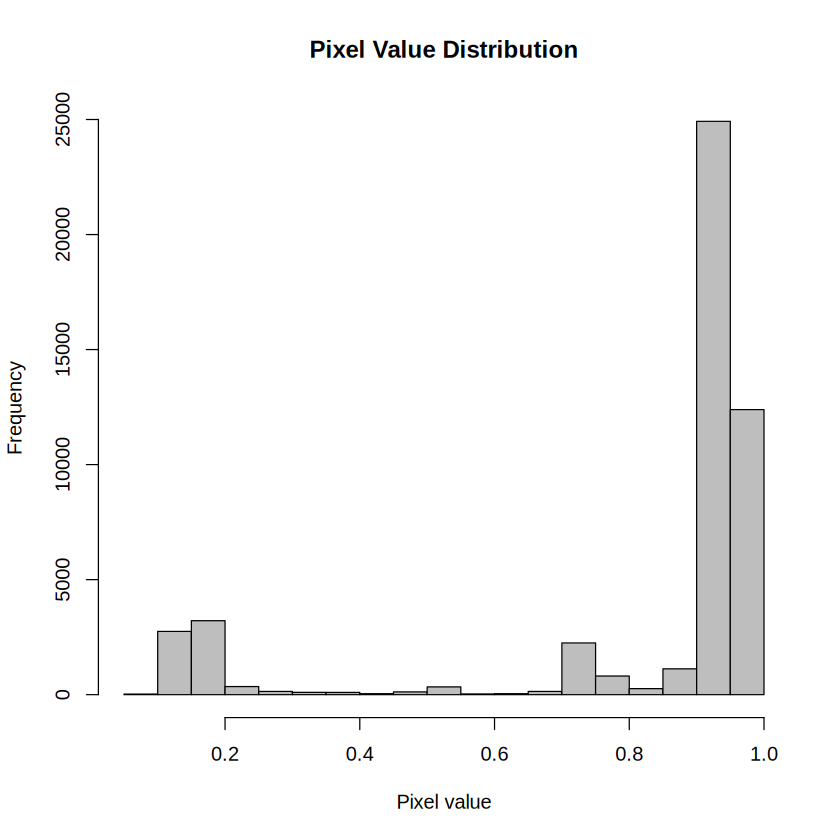

In [6]:
hist(as.numeric(pics[[1]]),
     main = "Pixel Value Distribution",
     xlab = "Pixel value",
     col = "grey")

In [7]:
str(pics[[1]])

 num [1:128, 1:128, 1:3] 0.902 0.902 0.902 0.902 0.902 ...


## 4. Resize the Images

Every image is resized to 28 × 28 pixels so all inputs have the same dimensions.

In [8]:
resize_image <- function(img, width = 28, height = 28) {
  old_height <- dim(img)[1]
  old_width <- dim(img)[2]

  row_index <- round(seq(1, old_height, length.out = height))
  col_index <- round(seq(1, old_width, length.out = width))

  row_index <- pmax(1, pmin(old_height, row_index))
  col_index <- pmax(1, pmin(old_width, col_index))

  img[row_index, col_index, , drop = FALSE]
}

pics <- lapply(pics, resize_image)
lapply(pics[1:2], dim)

$apple1.jpg
[1] 28 28  3

$apple2.jpg
[1] 28 28  3

## 5. Convert Images into Numeric Vectors

Each RGB image has 28 × 28 × 3 = 2,352 pixel values. These values become the input features for the neural network.

In [9]:
image_to_vector <- function(img) {
  as.numeric(img)
}

image_data <- do.call(rbind, lapply(pics, image_to_vector))
dim(image_data)

[1]   12 2352

## 6. Create Training and Testing Data

Use 8 images for training (4 from each category) and 4 for testing (2 from each category).

In [10]:
train_indices <- c(1:4, 7:10)
test_indices <- c(5:6, 11:12)

trainx <- image_data[train_indices, , drop = FALSE]
testx <- image_data[test_indices, , drop = FALSE]

trainy <- c(rep(0, 4), rep(1, 4))
testy <- c(rep(0, 2), rep(1, 2))

dim(trainx)
dim(testx)
length(trainy)
length(testy)

[1]    8 2352

[1]    4 2352

[1] 8

[1] 4

## 7. Encode the Labels

Class `0` represents an apple and class `1` represents a banana. One-hot encoding matches the model's two-unit softmax output.

In [11]:
trainLabels <- cbind(
  as.numeric(trainy == 0),
  as.numeric(trainy == 1)
)

testLabels <- cbind(
  as.numeric(testy == 0),
  as.numeric(testy == 1)
)

trainLabels
testLabels

1,0
1,0
1,0
1,0
0,1
0,1
0,1
0,1


1,0
1,0
0,1
0,1


## 8. Build the Neural Network

In [12]:
model <- keras_model_sequential(input_shape = c(2352)) |>
  layer_dense(units = 256, activation = "relu") |>
  layer_dense(units = 128, activation = "relu") |>
  layer_dense(units = 2, activation = "softmax")

summary(model)

Model: "sequential"
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                      ┃ Output Shape             ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                     │ (None, 256)              │       602,368 │
├───────────────────────────────────┼──────────────────────────┼───────────────┤
│ dense_1 (Dense)                   │ (None, 128)              │        32,896 │
├───────────────────────────────────┼──────────────────────────┼───────────────┤
│ dense_2 (Dense)                   │ (None, 2)                │           258 │
└───────────────────────────────────┴──────────────────────────┴───────────────┘
 Total params: 635,522 (2.42 MB)
 Trainable params: 635,522 (2.42 MB)
 Non-trainable params: 0 (0.00 B)


## 9. Compile the Model

In [13]:
compile(
  model,
  optimizer = optimizer_adam(),
  loss = "categorical_crossentropy",
  metrics = c("accuracy")
)

## 10. Train the Model

The model trains for 30 epochs. Because this is a very small dataset, results may vary and the model can easily overfit.

In [14]:
history <- fit(
  model,
  trainx,
  trainLabels,
  epochs = 30,
  batch_size = 2,
  validation_split = 0.25,
  verbose = 1
)

## 11. Evaluate the Model

In [15]:
results <- evaluate(model, testx, testLabels, verbose = 0)
print(results)

$accuracy
[1] 1

$loss
[1] 0.01148464



## 12. Predict Image Classes

In [16]:
prob <- predict(model, testx, verbose = 0)
pred <- max.col(prob) - 1

prediction_names <- ifelse(pred == 0, "Apple", "Banana")
actual_names <- ifelse(testy == 0, "Apple", "Banana")

data.frame(
  Image = image_files[test_indices],
  Apple_Probability = round(prob[, 1], 3),
  Banana_Probability = round(prob[, 2], 3),
  Predicted = prediction_names,
  Actual = actual_names
)

Image,Apple_Probability,Banana_Probability,Predicted,Actual
<chr>,<dbl>,<dbl>,<chr>,<chr>
apple5.jpg,0.998,0.002,Apple,Apple
apple6.jpg,0.992,0.008,Apple,Apple
banana5.jpg,0.022,0.978,Banana,Banana
banana6.jpg,0.014,0.986,Banana,Banana


## 13. Confusion Matrix

In [17]:
table(
  Predicted = prediction_names,
  Actual = actual_names
)

         Actual
Predicted Apple Banana
   Apple      2      0
   Banana     0      2

## Conclusion

This experiment demonstrates a basic image-classification workflow in R: reading images, resizing them, converting pixels into numeric features, encoding labels, training a neural network, and evaluating predictions. The generated dataset is small and illustrative, so its accuracy should not be interpreted as real-world performance.